In [1]:
import pandas as pd
import sys
from pathlib import Path 
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import numpy as np
import geopandas as gpd

sys.path.insert(0, str(Path("../src").resolve()))
from idx_exchange_data_science.preprocessing import initial_cleaning, clean_living_area, select_training_window,\
    filter_close_price, clean_lot_size, clean_coordinates, CoordinateImputer, add_property_age_at_sale, add_bed_bath_ratio,\
    clean_property_characteristics, clean_postal_code, add_binary_missing_indicators, clean_categorical_features,\
    add_school_district_features
    
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance

## Advanced Models: Decision Tree and Random Forest Regressors

This notebook develops and evaluates Decision Tree and Random Forest regression models to predict residential property closing prices (ClosePrice) using historical California real estate data. Their performance is compared against the baseline Linear Regression model.

### Data Loading and Preprocessing

The dataset consists of monthly CSV files from the California Regional Multiple Listing Service (CRMLS), covering January 2024 through April 2026.

The data is split chronologically into training, validation (March 2026), and test (April 2026) sets. Reusable cleaning functions from the idx_exchange.preprocessing_data_science module are applied to prepare the datasets for modeling.

Preprocessing parameters are learned from the training data, with fold-specific fitting used during cross-validation to prevent data leakage.

In [2]:
# Create a Path object to the folder containing the monthly CSV files
data_path = Path("../data")

# Get all the CSV files from the data folder and sort them chronologically by filename
csv_files = sorted(data_path.glob("*.csv"))

In [3]:
# Split the monthly CSV files into training, validation, and test sets
train_files = csv_files[:-2]
validation_file = csv_files[-2]
test_file = csv_files[-1]

In [4]:
# Read each monthly training file into a DataFrame
train_dfs = []

for file in train_files:
    monthly_data = pd.read_csv(file)

    # Extract the year and month from the CSV filename
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    monthly_data["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]
    
    train_dfs.append(monthly_data)
    
# Combine the monthly training DataFrames into a single DataFrame
initial_data = pd.concat(train_dfs, ignore_index=True)

/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1905/84281947.py:5: DtypeWarning: Columns (2,36,39,56,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1905/84281947.py:5: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1905/84281947.py:5: DtypeWarning: Columns (4,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)


In [5]:
# Load validation and test files
validation_df = pd.read_csv(validation_file)
test_df = pd.read_csv(test_file)

# Add source month to each dataset
for df, file in [(validation_df, validation_file), (test_df, test_file)]:
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    df["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]

### Initial Data Cleaning

Apply the initial cleaning rules to remove invalid records, including non-California properties, duplicate transactions, non-single-family residences, inconsistent dates, and invalid closing prices. The same cleaning rules are applied to all three datasets.

In [6]:
# Apply the initial cleaning rules to all datasets
clean_train_df, train_log = initial_cleaning(initial_data)
clean_validation_df, validation_log = initial_cleaning(validation_df)
clean_test_df, test_log = initial_cleaning(test_df)

In [7]:
display(train_log)

,step,Before,Removed,Removed (%),Remaining
0,California filtering,568074,76,0.0134,567998
1,Duplicate removal,567998,2911,0.5125,565087
2,Property-type filtering,565087,280370,49.6154,284717
3,Date consistency,284717,39,0.0137,284678
4,Target cleaning,284678,3,0.0011,284675


### Feature Selection

Select the relevant property features, target variable (ClosePrice), and tracking columns required for preprocessing and modeling. 

Features with 80% or more missing values are excluded from modeling. Based on the full 26 months training dataset, `BasementYN`, `BuildingAreaTotal`, and school-related columns exceed this threshold. 

Note: Detailed geographic layer using school districts will be added in Week 6 (Feature engineering). 

In [8]:
feature_columns = ["AttachedGarageYN", "BathroomsTotalInteger", "BedroomsTotal",
                   "City", "CountyOrParish", "FireplaceYN", "GarageSpaces", "Latitude",
                   "Longitude", "LivingArea","LotSizeSquareFeet", "LotSizeAcres", "NewConstructionYN",
                   "ParkingTotal", "PoolPrivateYN", "PostalCode", "ViewYN", "YearBuilt"]

target_column = ["ClosePrice"]
tracking_columns = ["SourceMonth", "CloseDate"]

key_columns = feature_columns + target_column + tracking_columns

In [9]:
clean_train_df = clean_train_df[key_columns].copy()
clean_validation_df = clean_validation_df[key_columns].copy()
clean_test_df = clean_test_df[key_columns].copy()

In [10]:
# Perserve the datasets before further preprocessing
base_train_df = clean_train_df.copy()
base_validation_df = clean_validation_df.copy()
base_test_df = clean_test_df.copy()

### Training Window Selection and Target Filtering

Select an adjustable training window of X months preceding March 2026. Calculate the 0.5th and 99.5th percentile ClosePrice thresholds from the selected training data and apply the same thresholds to the datasets according to the agreed cleaning rules.

In [11]:
X = 18  # Try 6, 12, 18

# Selcet training window 
clean_train_df = select_training_window(base_train_df, n_months=X, validation_month="2026-03")

print(f"Training window: {X} months")
print(f"Training records: {len(clean_train_df)}")

Training window: 18 months
Training records: 190549


In [12]:
# Calculate thresholds from the selected X-month training window
lower_threshold = clean_train_df["ClosePrice"].quantile(0.005)
upper_threshold = clean_train_df["ClosePrice"].quantile(0.995)

# Remove records outside the training-derived ClosePrice thresholds
clean_train_df, train_price_log = filter_close_price(clean_train_df, lower_threshold, upper_threshold)
clean_validation_df, validation_price_log = filter_close_price(clean_validation_df, lower_threshold, upper_threshold)
clean_test_df, test_price_log = filter_close_price(clean_test_df, lower_threshold, upper_threshold)

In [13]:
# # Apply log transformation to ClosePrice for all datasets
for df in[clean_train_df, clean_validation_df, clean_test_df]:
    df["LogClosePrice"] = np.log1p(df["ClosePrice"])

### Numerical Feature Cleaning

#### LivingArea and LotSizeSquareFeet

Clean numerical property features by removing records with nonpositive LivingArea values while retaining missing values for later imputation. Standardize lot-size measurements by converting valid acreage values to square feet when LotSizeSquareFeet is missing.

In [14]:
# Remove nonpositive LivingArea values while retaining missing values
clean_train_df, train_area_log = clean_living_area(clean_train_df)
clean_validation_df, validation_log = clean_living_area(clean_validation_df)
clean_test_df, test_log = clean_living_area(clean_test_df)

In [15]:
# Clean lot sizes and recover missing square footage using acres
clean_train_df, train_recovered_rows = clean_lot_size(clean_train_df)
clean_validation_df, validation_recovered_rows = clean_lot_size(clean_validation_df)
clean_test_df, test_recovered_rows = clean_lot_size(clean_test_df)

In [16]:
# Summarize the number of recovered lot-size values in each dataset
display(pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Lot sizes recovered": [train_recovered_rows, validation_recovered_rows, test_recovered_rows]}))

,Dataset,Lot sizes recovered
0,Training,15
1,Validation,2
2,Test,0


#### Property Characteristics 

Property characteristics, including bedrooms, bathrooms, garage spaces, and parking counts, are evaluated using provisional plausibility ranges. Invalid values are marked as missing for later imputation rather than removing the corresponding records.

These cleaning rules have not yet been finalized and may be revised following team discussion and further review.

In [17]:
# Clean property characteristics and record invalid values
clean_train_df, train_property_log = clean_property_characteristics(clean_train_df)
clean_validation_df, validation_property_log = clean_property_characteristics(clean_validation_df)
clean_test_df, test_property_log = clean_property_characteristics(clean_test_df)

In [18]:
# Summarize invalid property characteristic values
property_logs = pd.DataFrame({ "Training": train_property_log,
                               "Validation": validation_property_log,
                               "Test": test_property_log})

display(property_logs)

,Training,Validation,Test
BedroomsTotal,61,6,2
BathroomsTotalInteger,44,5,3
GarageSpaces,343,19,21
ParkingTotal,707,45,38


### Geographic Feature Cleaning

Standardize postal codes to five-digit ZIP codes and mark latitude and longitude values outside California's geographic bounds as missing. Missing coordinates will be imputed later using training-derived ZIP-level, county-level, and overall medians within the modeling pipeline.

In [19]:
# Standardize postal codes for all datasets
clean_train_df = clean_postal_code(clean_train_df)
clean_validation_df = clean_postal_code(clean_validation_df)
clean_test_df = clean_postal_code(clean_test_df)

In [20]:
# Mark invalid coordinates as missing
clean_train_df = clean_coordinates(clean_train_df)
clean_validation_df = clean_coordinates(clean_validation_df)
clean_test_df = clean_coordinates(clean_test_df)

### Feature Engineering

Calculate property age and create missingness indicators for binary property features. Missing values are retained for imputation within the modeling pipeline.

In [21]:
# Calculate property age at sale for all datasets
clean_train_df = add_property_age_at_sale(clean_train_df)
clean_validation_df = add_property_age_at_sale(clean_validation_df)
clean_test_df = add_property_age_at_sale(clean_test_df)

In [22]:
# Apply missingness indicator for binary features to all datasets
clean_train_df = add_binary_missing_indicators(clean_train_df)
clean_validation_df = add_binary_missing_indicators(clean_validation_df)
clean_test_df = add_binary_missing_indicators(clean_test_df)

### Categorical Feature Cleaning

Standardize `City`, `CountyOrParish`, and `PostalCode` by converting values to strings, removing surrounding whitespace, and replacing missing values with `"Unknown"`.

Target encoding will be performed within the modeling pipeline. The encoding approach is provisional and subject to further team review.

In [23]:
# Standardize categorical features for target encoding
clean_train_df = clean_categorical_features(clean_train_df)
clean_validation_df = clean_categorical_features(clean_validation_df)
clean_test_df = clean_categorical_features(clean_test_df)

## Preprocessing Pipeline

Define preprocessing steps for numerical, binary, and categorical features using sklearn pipelines. Missing values are imputed using training-derived statistics, numerical features are standardized, and categorical features are target-encoded.

Learned preprocessing parameters within the modeling pipeline are fitted separately for each cross-validation training fold to reduce data leakage. Fixed data-cleaning rules and training-derived ClosePrice thresholds are applied before cross-validation

In [24]:
# define the columns used by each pipeline.
area_columns = ["LivingArea", "LotSizeSquareFeet"]
property_columns = ["BedroomsTotal", "BathroomsTotalInteger", "GarageSpaces", "ParkingTotal"]
coordinate_columns = ["Latitude", "Longitude"]
age_columns = ["PropertyAgeAtSale"]
binary_columns = ["AttachedGarageYN", "FireplaceYN", "NewConstructionYN", "PoolPrivateYN", "ViewYN"]
binary_missing_columns = [f"{col}_Missing" for col in binary_columns]
categorical_columns = ["City", "CountyOrParish","PostalCode"]

In [25]:
# Impute, log-transform, and standardize area features
area_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scaling", StandardScaler())])

# Impute property counts using mode, then standardize
property_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                              ("scaling", StandardScaler())])

# Impute and standardize property age
property_age_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                                  ("scaling", StandardScaler())])

# Standardize coordinates after geographic imputation
coordinate_pipeline = Pipeline([("scaling", StandardScaler())])

# Impute binary features using mode
binary_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent"))])

# Encode high-cardinality categorical features
categorical_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5,\
                                                                   shuffle=True, random_state=42))])

In [26]:
# Build the ColumnTransformer by assigning each pipeline to its corresponding features.
preprocessor = ColumnTransformer([("area", area_pipeline, area_columns),
                                  ("property", property_pipeline, property_columns),
                                  ("coordinates", coordinate_pipeline, coordinate_columns),
                                  ("property_age", property_age_pipeline, age_columns),
                                  ("binary", binary_pipeline, binary_columns),
                                  ("binary_missing", "passthrough", binary_missing_columns),
                                  ("categorical", categorical_pipeline, categorical_columns)])

In [27]:
# Build the complete modeling pipeline
default_tree_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                           ("preprocessing", preprocessor),
                           ("model", DecisionTreeRegressor(random_state=42))])

In [28]:
# Build the complete modeling pipeline
decision_tree_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                           ("preprocessing", preprocessor),
                           ("model", DecisionTreeRegressor(random_state=42, max_depth=15, min_samples_leaf=10))])

In [29]:
# Build the Random Forest modeling pipeline
random_forest_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                   ("preprocessing", preprocessor),
                                   ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))])

In [30]:
# Prepare features and target 
model_features = (area_columns + property_columns + coordinate_columns +\
                  age_columns + binary_columns + binary_missing_columns + categorical_columns)

X_train = clean_train_df[model_features].copy()
y_train = clean_train_df["LogClosePrice"]

X_val = clean_validation_df[model_features].copy()
y_val = clean_validation_df["LogClosePrice"]

### Month-Based Cross-Validation

Use expanding-window cross-validation to evaluate the default and regularized Decision Tree models on chronological monthly splits.

Each fold trains on all preceding months and validates on the following month. The entire preprocessing pipeline is fitted independently within each training fold to prevent data leakage.

In [31]:
# Sort training records chronologically by source month
train_sorted = clean_train_df.sort_values("SourceMonth", kind="stable")

# Identify available training months
months = sorted(train_sorted["SourceMonth"].unique())

# Use the last five months for validation
validation_months = months[-5:]

cv_splits = []

for validation_month in validation_months:

    train_idx = np.where(train_sorted["SourceMonth"] < validation_month)[0]
    val_idx = np.where(train_sorted["SourceMonth"] == validation_month)[0]

    cv_splits.append((train_idx, val_idx))

In [32]:
# Calculate Mean Absolute Percentage Error
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Median Absolute Percentage Error
def mdape(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100

In [33]:
# Custom scorer (calculate R² on the original ClosePrice scale)
def close_price_r2(estimator, X, y):
    predictions_log = estimator.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return r2_score(actual_prices, predicted_prices)

def dollar_mape(estimator, X, y):
    return mape(np.expm1(y), np.expm1(estimator.predict(X)))

def dollar_mdape(estimator, X, y):
    return mdape(np.expm1(y), np.expm1(estimator.predict(X)))

### Month-Based Cross-Validation Results

Random Forest achieved the highest mean cross-validation R² of `0.8862`, with a MAPE of `11.68%` and an MdAPE of `7.74%` across five monthly validation folds.

The regularized Decision Tree also improved upon the baseline Linear Regression model, achieving a mean R² of `0.8525`, compared with `0.8003` for Linear Regression.

The default Decision Tree performed less consistently, with a mean R² of `0.7872`, highlighting the importance of controlling tree complexity.

Overall, Random Forest demonstrated the strongest cross-validation performance, suggesting that ensemble learning and the ability to capture nonlinear relationships improve prediction accuracy for residential property closing prices.

In [34]:
# Prepare chronologically sorted features and target for cross-validation
X_cv = train_sorted[model_features].copy()
y_cv = train_sorted["LogClosePrice"]

# Compare default and regularized Decision Trees
cv_results = []

for name, pipeline in [("Default Decision Tree", default_tree_pipeline), ("Regularized Decision Tree", decision_tree_pipeline),\
                       ("Random Forest", random_forest_pipeline)]:
    scores = cross_validate(pipeline, X_cv, y_cv, cv=cv_splits,
                            scoring={"R²": close_price_r2, "MAPE": dollar_mape,"MdAPE": dollar_mdape}, n_jobs=-1)

    cv_results.append({"Model": name, "Mean CV R²": scores["test_R²"].mean(),
        "Mean CV MAPE (%)": scores["test_MAPE"].mean(), "Mean CV MdAPE (%)": scores["test_MdAPE"].mean()})

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

,Model,Mean CV R²,Mean CV MAPE (%),Mean CV MdAPE (%)
0,Default Decision Tree,0.767311,16.965413,10.936460
1,Regularized Decision Tree,0.840492,14.261738,9.635359
2,Random Forest,0.880331,11.918747,7.894977


In [35]:
# Display training and validation periods for each fold
for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    train_months = train_sorted.iloc[train_idx]["SourceMonth"]
    val_months = train_sorted.iloc[val_idx]["SourceMonth"]

    print(f"Fold {i}: "f"Train {train_months.min()} to {train_months.max()} | "
          f"Validate {val_months.iloc[0]}")

Fold 1: Train 2024-09 to 2025-09 | Validate 2025-10
Fold 2: Train 2024-09 to 2025-10 | Validate 2025-11
Fold 3: Train 2024-09 to 2025-11 | Validate 2025-12
Fold 4: Train 2024-09 to 2025-12 | Validate 2026-01
Fold 5: Train 2024-09 to 2026-01 | Validate 2026-02


### Model Fitting and Validation Results

The default Decision Tree Regressor achieved a training R² of `0.9575` and a validation R² of `0.7886`, indicating overfitting. After limiting tree depth and increasing the minimum samples per leaf, the regularized Decision Tree achieved a training R² of `0.9036` and a validation R² of `0.8625`. The smaller gap suggests reduced overfitting and improved generalization.

Random Forest achieved the highest validation R² of `0.8885`, with a MAPE of `11.30%` and an MdAPE of `7.67%`. Although its training R² of `0.9683` suggests some overfitting, its strong validation performance and consistent cross-validation results indicate better predictive accuracy than both Decision Tree configurations. Overall, Random Forest demonstrated the strongest predictive performance among the evaluated models.

In [36]:
# Fit and evaluate all models on training and validation datasets
validation_results = []

for name, pipeline in [
    ("Default Decision Tree", default_tree_pipeline),
    ("Regularized Decision Tree", decision_tree_pipeline),
    ("Random Forest", random_forest_pipeline)]:
    
    # Fit the complete pipeline on the full training dataset
    pipeline.fit(X_train, y_train)

    # Generate predictions on the original ClosePrice scale
    train_predictions = np.expm1(pipeline.predict(X_train))
    val_predictions = np.expm1(pipeline.predict(X_val))

    # Calculate evaluation metrics
    train_r2 = r2_score(np.expm1(y_train), train_predictions)
    val_r2 = r2_score(np.expm1(y_val), val_predictions)
    val_mape = mape(np.expm1(y_val), val_predictions)
    val_mdape = mdape(np.expm1(y_val), val_predictions)

    # Store model results
    validation_results.append({"Model": name, "Training R²": train_r2, "Validation R²": val_r2,
                               "Validation MAPE (%)": val_mape, "Validation MdAPE (%)": val_mdape})

# Create comparison DF
validation_results_df = pd.DataFrame(validation_results)

display(validation_results_df.round(4))

,Model,Training R²,Validation R²,Validation MAPE (%),Validation MdAPE (%)
0,Default Decision Tree,0.9560,0.7863,16.1685,10.7692
1,Regularized Decision Tree,0.8989,0.8490,13.7512,9.5891
2,Random Forest,0.9648,0.8826,11.4503,7.7477


In [37]:
# Add Linear Regression baseline validation results
baseline_validation = pd.DataFrame([{"Model": "Linear Regression", "Training R²": 0.8179, 
                                     "Validation R²": 0.796876, "Validation MAPE (%)": 15.820403,
                                     "Validation MdAPE (%)": 12.014128}])

# Combine baseline with advanced model results
validation_comparison_df = pd.concat([baseline_validation, validation_results_df],ignore_index=True)

display(validation_comparison_df)

,Model,Training R²,Validation R²,Validation MAPE (%),Validation MdAPE (%)
0,Linear Regression,0.817900,0.796876,15.820403,12.014128
1,Default Decision Tree,0.956011,0.786273,16.168467,10.769231
2,Regularized Decision Tree,0.898904,0.849028,13.751175,9.589114
3,Random Forest,0.964754,0.882614,11.450329,7.747740


### April 2026 Test Results

The three tree-based models were evaluated on the held-out April 2026 test dataset and compared against the Linear Regression baseline. The default Decision Tree achieved a test R² of `0.8048`, slightly below the Linear Regression baseline of `0.8093`. The regularized Decision Tree improved test performance to `0.8548`, demonstrating that limiting tree complexity helps reduce overfitting and improve generalization.

Random Forest achieved the highest test R² of `0.8893`, with a MAPE of `11.55%` and an MdAPE of `7.78%`. Its test performance was consistent with the month-based cross-validation and March 2026 validation results. Overall, Random Forest demonstrated the strongest predictive performance outperforming the Linear Regression baseline and both Decision Tree configurations on the held-out test dataset.

In [38]:
# Prepare the April 2026 test dataset
X_test = clean_test_df[model_features].copy()
y_test = clean_test_df["LogClosePrice"]

# Convert actual values to the original ClosePrice scale
y_test_actual = np.expm1(y_test)

# Store test evaluation results
test_results = []

for name, pipeline in [("Default Decision Tree", default_tree_pipeline),
                       ("Regularized Decision Tree", decision_tree_pipeline),
                       ("Random Forest", random_forest_pipeline)]:
    
    # Predict ClosePrice for the April 2026 test dataset
    test_predictions_log = pipeline.predict(X_test)

    # Convert predictions to the original dollar scale
    test_predictions = np.expm1(test_predictions_log)

    # Calculate test metrics in dallor scale
    test_r2 = r2_score(y_test_actual, test_predictions)
    test_mape = mape(y_test_actual, test_predictions)
    test_mdape = mdape(y_test_actual, test_predictions)

    # Store the results
    test_results.append({"Model": name, "Test R²": test_r2, "Test MAPE (%)": test_mape,
                         "Test MdAPE (%)": test_mdape})

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,Model,Test R²,Test MAPE (%),Test MdAPE (%)
0,Default Decision Tree,0.785325,16.469703,10.792350
1,Regularized Decision Tree,0.851582,13.955753,9.565793
2,Random Forest,0.888182,11.726740,7.867963


### Model Behavior (Strengths/Weaknesses)

**Default Decision Tree:** The model achieved a high training R² of `0.9575` but a considerably lower validation R² of `0.7886`, indicating overfitting. Although Decision Trees can capture nonlinear relationships and are relatively interpretable, unrestricted tree growth can reduce generalization performance.

**Regularized Decision Tree:** Limiting the maximum depth to 15 and requiring at least 10 samples per leaf reduced overfitting. The model achieved a training R² of `0.9036` and a validation R² of `0.8625`, demonstrating improved generalization.

**Random Forest:** The model achieved the highest validation of R² `0.8885` and test of R² `0.8893`. By averaging predictions across multiple trees, Random Forest reduces the variance associated with individual decision trees. However, it is more computationally expensive and its higher training R² of `0.9683` also indicates some remaining overfitting.

In [39]:
baseline_test = pd.DataFrame([{"Model": "Linear Regression", "Test R²": 0.8091,
                               "Test MAPE (%)": 15.8561, "Test MdAPE (%)": 11.9001}])

test_comparison_df = pd.concat([baseline_test, test_results_df], ignore_index=True)
display(test_comparison_df)

,Model,Test R²,Test MAPE (%),Test MdAPE (%)
0,Linear Regression,0.809100,15.856100,11.900100
1,Default Decision Tree,0.785325,16.469703,10.792350
2,Regularized Decision Tree,0.851582,13.955753,9.565793
3,Random Forest,0.888182,11.726740,7.867963


## Additional Feature Engineering

This section introduces additional features to capture property characteristics and geographicinformation that may improve home sale price predictions. Model performance will be compared against the original baseline models.

### Bedroom to Bathroom Ratio
Create a `BedBathRatio` feature to capture the relationship between the number of bedrooms and bathrooms in a property.

In [40]:
# Create copies to preserve the original datasets
train_fe = clean_train_df.copy()
validation_fe = clean_validation_df.copy()
test_fe = clean_test_df.copy()

# Add bedroom to bathroom ratio
train_fe = add_bed_bath_ratio(train_fe)
validation_fe = add_bed_bath_ratio(validation_fe)
test_fe = add_bed_bath_ratio(test_fe)

### School District Features

Add school district features using the California School District Areas 2024–25 GeoJSON dataset. Property coordinates are spatially joined with school district boundaries to identify the corresponding elementary and high school districts. Unified districts are assigned to both categories.

In [41]:
# Load California school district boundaries
districts_df = gpd.read_file("../external_data/GeoJSON.geojson")

# Inspect school district data
print(f"Total school districts: {len(districts_df):,}")
print(f"Coordinate Reference System: {districts_df.crs}")
print("School districts by type:")
print(districts_df["DistrictType"].value_counts(dropna=False))

Total school districts: 937
Coordinate Reference System: EPSG:4326
School districts by type:
DistrictType
Elementary    516
Unified       345
High           76
Name: count, dtype: int64


In [42]:
# Convert property coords into geographic points
train_geo = gpd.GeoDataFrame(train_fe.copy(), geometry=gpd.points_from_xy(
    train_fe["Longitude"], train_fe["Latitude"]), crs="EPSG:4326")

validation_geo = gpd.GeoDataFrame(validation_fe.copy(),
    geometry=gpd.points_from_xy(validation_fe["Longitude"], validation_fe["Latitude"]), crs="EPSG:4326")

test_geo = gpd.GeoDataFrame(test_fe.copy(),
    geometry=gpd.points_from_xy(test_fe["Longitude"], test_fe["Latitude"]), crs="EPSG:4326")

In [43]:
# Elementary school districts (including unified districts)
elementary_districts = districts_df[districts_df["DistrictType"].
     isin(["Elementary", "Unified"])][["DistrictName", "DistrictType", "geometry"]].copy()

# High school districts (including unified districts)
high_school_districts = districts_df[districts_df["DistrictType"].
    isin(["High", "Unified"])][["DistrictName", "DistrictType", "geometry"]].copy()

# Rename columns to match our new features
elementary_districts = elementary_districts.rename(
    columns={"DistrictName": "ElementarySchoolDistrict"})

high_school_districts = high_school_districts.rename(
    columns={"DistrictName": "HighSchoolDistrict"})

In [44]:
# Add school district features to training data
train_fe = add_school_district_features(train_fe, elementary_districts,high_school_districts)

# Add school district features to validation data
validation_fe = add_school_district_features(validation_fe, elementary_districts,high_school_districts)

# Add school district features to test data
test_fe = add_school_district_features(test_fe, elementary_districts, high_school_districts)

### School District Feature Engineering Summary

School district features were assigned to the training, validation, and test datasets using spatial joins. Elementary and high school districts were identified separately, with unified districts included in both categories.

The spatial joins preserved the original number of property records across all three datasets. In the training set, 138 properties had missing elementary school district assignments, while 260 had missing high school district assignments. Missing school district values were retained and handled as a separate category by TargetEncoder.

In [45]:
# Verify row counts
print("Training:", len(train_fe), len(clean_train_df))
print("Validation:", len(validation_fe), len(clean_validation_df))
print("Test:", len(test_fe), len(clean_test_df))

# Check missing district assignments
print(train_fe[["ElementarySchoolDistrict", "HighSchoolDistrict"]].isna().sum())

Training: 188590 188590
Validation: 11390 11390
Test: 12312 12312
ElementarySchoolDistrict    138
HighSchoolDistrict          260
dtype: int64


In [46]:
# Impute missing bedroom to bathroom ratios using median and then standardize
ratio_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                           ("scaling", StandardScaler())])
ratio_column = ["BedBathRatio"]
school_district_columns = ["ElementarySchoolDistrict", "HighSchoolDistrict"]

# Target encoding for school district features
school_district_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5, shuffle=True, random_state=42))])

### Feature-Engineered Preprocessing

Two preprocessing configurations are created to evaluate the contribution of the engineered features:
* Bedroom to Bathroom Ratio: Extends the baseline preprocessor with the BedBathRatio feature, using median imputation and standardization.
* Bedroom to Bathroom Ratio + School Districts: Adds school district features to the ratio-based preprocessor using target encoding with cross-fitting to reduce target leakage.

In [47]:
# Extend baseline preprocessing with bedroom to bathroom ratio
preprocessor_ratio = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),

    # New feature
    ("bed_bath_ratio", ratio_pipeline, ratio_column)])

In [48]:
# Extend baseline preprocessing with both engineered features
preprocessor_fe = ColumnTransformer([
    ("area", area_pipeline, area_columns),
    ("property", property_pipeline, property_columns),
    ("coordinates", coordinate_pipeline, coordinate_columns),
    ("property_age", property_age_pipeline, age_columns),
    ("binary", binary_pipeline, binary_columns),
    ("binary_missing", "passthrough", binary_missing_columns),
    ("categorical", categorical_pipeline, categorical_columns),
    # New features
    ("bed_bath_ratio", ratio_pipeline, ratio_column),
    ("school_district", school_district_pipeline, school_district_columns)])

In [50]:
# Additional engineered features
ratio_features = ["BedBathRatio"]
new_feature_columns = ["BedBathRatio", "ElementarySchoolDistrict", "HighSchoolDistrict"]

# Create copies of the original modeling datasets
X_train_ratio = X_train.copy()
X_validation_ratio = X_val.copy()
X_test_ratio = X_test.copy()

X_train_fe = X_train.copy()
X_validation_fe = X_val.copy()
X_test_fe = X_test.copy()

# Add bedroom to bathroom ratio
for X, df in [(X_train_ratio, train_fe), (X_validation_ratio, validation_fe), (X_test_ratio, test_fe)]:
    X["BedBathRatio"] = df["BedBathRatio"]

# Add all engineered features
for X, df in [(X_train_fe, train_fe), (X_validation_fe, validation_fe), (X_test_fe, test_fe)]:
    for col in new_feature_columns:
        X[col] = df[col]

# Define model feature lists
model_features_ratio = model_features + ratio_features
model_features_fe = model_features + new_feature_columns

Linear Regression, Decision Tree, and Random Forest pipelines are constructed using two feature sets: bedroom-to-bathroom ratio only, and bedroom-to-bathroom ratio combined with school district features. The same model configurations are used across feature sets to evaluate the impact of feature engineering.

In [51]:
# Linear Regression with bedroom to bathroom ratio
linear_regression_pipeline_ratio = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                             ("preprocessing", preprocessor_ratio),("model", LinearRegression())])

# Linear Regression with both engineered features
linear_regression_pipeline_fe = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                          ("preprocessing", preprocessor_fe), ("model", LinearRegression())])

In [52]:
# Decision Tree with bedroom to bathroom ratio
decision_tree_pipeline_ratio = Pipeline([("coordinate_imputation", CoordinateImputer()),
    ("preprocessing", preprocessor_ratio), ("model", DecisionTreeRegressor(
                                                      random_state=42, max_depth=15, min_samples_leaf=10))])

# Decision Tree with both engineered features
decision_tree_pipeline_fe = Pipeline([("coordinate_imputation", CoordinateImputer()),
    ("preprocessing", preprocessor_fe), ("model", DecisionTreeRegressor(
                                                   random_state=42, max_depth=15, min_samples_leaf=10))])

In [53]:
# Random Forest with bedroom to bathroom ratio
random_forest_pipeline_ratio = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                         ("preprocessing", preprocessor_ratio), ("model", RandomForestRegressor(
                                                            n_estimators=100, random_state=42, n_jobs=-1))])

# Random Forest with both engineered features
random_forest_pipeline_fe = Pipeline([("coordinate_imputation", CoordinateImputer()),
                                      ("preprocessing", preprocessor_fe), ("model", RandomForestRegressor(
                                                         n_estimators=100, random_state=42, n_jobs=-1))])

In [54]:
# Sort feature-engineered training data using the same order as baseline
train_sorted_fe = train_fe.sort_values("SourceMonth").reset_index(drop=True)

# Prepare features for both experiments
X_cv_ratio = train_sorted_fe[model_features_ratio].copy()
X_cv_fe = train_sorted_fe[model_features_fe].copy()

# Target variable
y_cv_fe = train_sorted_fe["LogClosePrice"].copy()

### Month-Based Cross-Validation Results
* Linear Regression: Adding school district features slightly decreased mean CV R² from `0.7791` to `0.7775`.
* Decision Tree: Performance remained nearly unchanged, with a slight increase in R² from `0.8434` to `0.8441`.
* Random Forest: Achieved the best overall performance. Adding school district features improved mean CV R² from `0.8800` to `0.8818`, reduced MAPE from `11.93%` to `11.86%`, and reduced MdAPE from `7.92%` to `7.89%`.

In [55]:
# Evaluate feature-engineered models using month-based cross-validation
cv_results_fe = []

for name, pipeline, X in [
    ("Linear Regression + Ratio", linear_regression_pipeline_ratio, X_cv_ratio),
    ("Decision Tree + Ratio", decision_tree_pipeline_ratio, X_cv_ratio),
    ("Random Forest + Ratio", random_forest_pipeline_ratio, X_cv_ratio),
    ("Linear Regression + Ratio + School Districts", linear_regression_pipeline_fe, X_cv_fe),
    ("Decision Tree + Ratio + School Districts", decision_tree_pipeline_fe, X_cv_fe),
    ("Random Forest + Ratio + School Districts", random_forest_pipeline_fe, X_cv_fe)]:

    scores = cross_validate(pipeline, X, y_cv_fe, cv=cv_splits,\
                scoring={ "R2": close_price_r2, "MAPE": dollar_mape, "MdAPE": dollar_mdape}, n_jobs=1)

    cv_results_fe.append({"Model": name,
        "Mean CV R²": scores["test_R2"].mean(),
        "Mean CV MAPE (%)": scores["test_MAPE"].mean(),
        "Mean CV MdAPE (%)": scores["test_MdAPE"].mean()})

cv_results_fe_df = pd.DataFrame(cv_results_fe)
display(cv_results_fe_df.round(4))

,Model,Mean CV R²,Mean CV MAPE (%),Mean CV MdAPE (%)
0,Linear Regression + Ratio,0.7791,16.0189,11.8403
1,Decision Tree + Ratio,0.8434,14.1650,9.5123
2,Random Forest + Ratio,0.8800,11.9297,7.9213
3,Linear Regression + Ratio + School Districts,0.7775,15.8995,11.6824
4,Decision Tree + Ratio + School Districts,0.8441,14.1687,9.5106
5,Random Forest + Ratio + School Districts,0.8818,11.8600,7.8867


### Validation Set Evaluation (Feature-Engineered Models)

The models are fitted on the full training dataset and evaluate on the held-out March 2026 validation set. Performance is measured using R², MAPE, and MdAPE on the original dollar scale.

In [56]:
# Fit and evaluate feature-engineered models on training and validation datasets
validation_results_fe = []

for name, pipeline, X_train_model, X_val_model in [
    ("Linear Regression + Ratio", linear_regression_pipeline_ratio, X_train_ratio, X_validation_ratio),
    ("Decision Tree + Ratio", decision_tree_pipeline_ratio, X_train_ratio, X_validation_ratio),
    ("Random Forest + Ratio", random_forest_pipeline_ratio, X_train_ratio, X_validation_ratio),
    ("Linear Regression + Ratio + School Districts", linear_regression_pipeline_fe, X_train_fe, X_validation_fe),
    ("Decision Tree + Ratio + School Districts", decision_tree_pipeline_fe, X_train_fe, X_validation_fe),
    ("Random Forest + Ratio + School Districts", random_forest_pipeline_fe, X_train_fe, X_validation_fe)]:

    # Fit the complete pipeline on the full training dataset
    pipeline.fit(X_train_model, y_train)

    # Generate predictions on the original ClosePrice scale
    train_predictions = np.expm1(pipeline.predict(X_train_model))
    val_predictions = np.expm1(pipeline.predict(X_val_model))

    # Calculate evaluation metrics
    train_r2 = r2_score(np.expm1(y_train), train_predictions)
    val_r2 = r2_score(np.expm1(y_val), val_predictions)
    val_mape = mape(np.expm1(y_val), val_predictions)
    val_mdape = mdape(np.expm1(y_val), val_predictions)

    # Store model results
    validation_results_fe.append({"Model": name, "Training R²": train_r2, "Validation R²": val_r2,
                                  "Validation MAPE (%)": val_mape, "Validation MdAPE (%)": val_mdape})

# Create comparison DataFrame
validation_results_fe_df = pd.DataFrame(validation_results_fe)
validation_comparison_df
display(validation_results_fe_df.round(4))

,Model,Training R²,Validation R²,Validation MAPE (%),Validation MdAPE (%)
0,Linear Regression + Ratio,0.8145,0.7891,15.6720,11.7796
1,Decision Tree + Ratio,0.8989,0.8459,13.8286,9.5567
2,Random Forest + Ratio,0.9650,0.8826,11.4464,7.7208
3,Linear Regression + Ratio + School Districts,0.8151,0.7877,15.5106,11.6943
4,Decision Tree + Ratio + School Districts,0.9007,0.8484,13.6959,9.4262
5,Random Forest + Ratio + School Districts,0.9640,0.8845,11.3881,7.6614


### Validation Performance Comparison

All models were trained on the complete training dataset and evaluated on the held-out March 2026 validation set. Performance was assessed using R², MAPE, and MdAPE on the original dollar scale.

**Key Findings:**

* Random Forest: Achieved the best overall validation performance. Adding both the bedroom to bathroom ratio and school district features improved R² from 0.8826 to 0.8845, while reducing MAPE from 11.45% to 11.39% and MdAPE from 7.75% to 7.66%.

* Decision Tree: Feature engineering produced mixed results. The combined features slightly reduced validation R² compared with the baseline (0.8490 to 0.8484), but improved MAPE and MdAPE.

* Linear Regression: Adding school district features to the ratio-based model slightly reduced R² but improved percentage-based error metrics.

Overall, the Random Forest with both engineered features achieved the strongest validation performance. However, the improvements were modest, suggesting that the additional features provide limited incremental predictive value.

In [57]:
# Combine baseline and feature-engineered validation results
validation_comparison_df = pd.concat([validation_results_df, validation_results_fe_df], ignore_index=True)
display(validation_comparison_df.round(4))

,Model,Training R²,Validation R²,Validation MAPE (%),Validation MdAPE (%)
0,Default Decision Tree,0.9560,0.7863,16.1685,10.7692
1,Regularized Decision Tree,0.8989,0.8490,13.7512,9.5891
2,Random Forest,0.9648,0.8826,11.4503,7.7477
3,Linear Regression + Ratio,0.8145,0.7891,15.6720,11.7796
4,Decision Tree + Ratio,0.8989,0.8459,13.8286,9.5567
5,Random Forest + Ratio,0.9650,0.8826,11.4464,7.7208
6,Linear Regression + Ratio + School Districts,0.8151,0.7877,15.5106,11.6943
7,Decision Tree + Ratio + School Districts,0.9007,0.8484,13.6959,9.4262
8,Random Forest + Ratio + School Districts,0.9640,0.8845,11.3881,7.6614


In [58]:
# Calculate permutation importance for all three models
importance_results = []

for name, pipeline in [("Linear Regression", linear_regression_pipeline_fe), ("Decision Tree", decision_tree_pipeline_fe),
                       ("Random Forest", random_forest_pipeline_fe)]:

    perm_importance = permutation_importance(pipeline, X_validation_fe, y_val, scoring=close_price_r2,
                                             n_repeats=5, random_state=42, n_jobs=1)
    importance_results.append(pd.Series(perm_importance.importances_mean, index=X_validation_fe.columns, name=name))

# Combine feature importance into one DataFrame
feature_importance_df = pd.concat(importance_results, axis=1)
# Sort features by Random Forest importance
feature_importance_df = feature_importance_df.sort_values("Random Forest", ascending=False)
display(feature_importance_df.round(4))

,Linear Regression,Decision Tree,Random Forest
PostalCode,0.4552,0.7087,0.6853
LivingArea,0.1593,0.4114,0.3747
Longitude,0.0363,0.0609,0.0388
ElementarySchoolDistrict,0.0115,0.0393,0.0281
City,0.0155,0.0429,0.0224
Latitude,0.0266,0.0315,0.0215
LotSizeSquareFeet,-0.0018,0.0153,0.0169
HighSchoolDistrict,0.0132,0.0210,0.0164
PropertyAgeAtSale,0.0037,0.0191,0.0158
BathroomsTotalInteger,0.1075,0.0041,0.0126


### Permutation Feature Importance Comparison

Permutation importance was calculated on the March 2026 validation set for Linear Regression, Decision Tree, and Random Forest models using both engineered feature types.

All three models consistently identified location (PostalCode) and property size (LivingArea) as the most important predictors of sale prices. School district features also showed positive importance across all models, suggesting additional predictive value. In contrast, several binary features had relatively low importance.

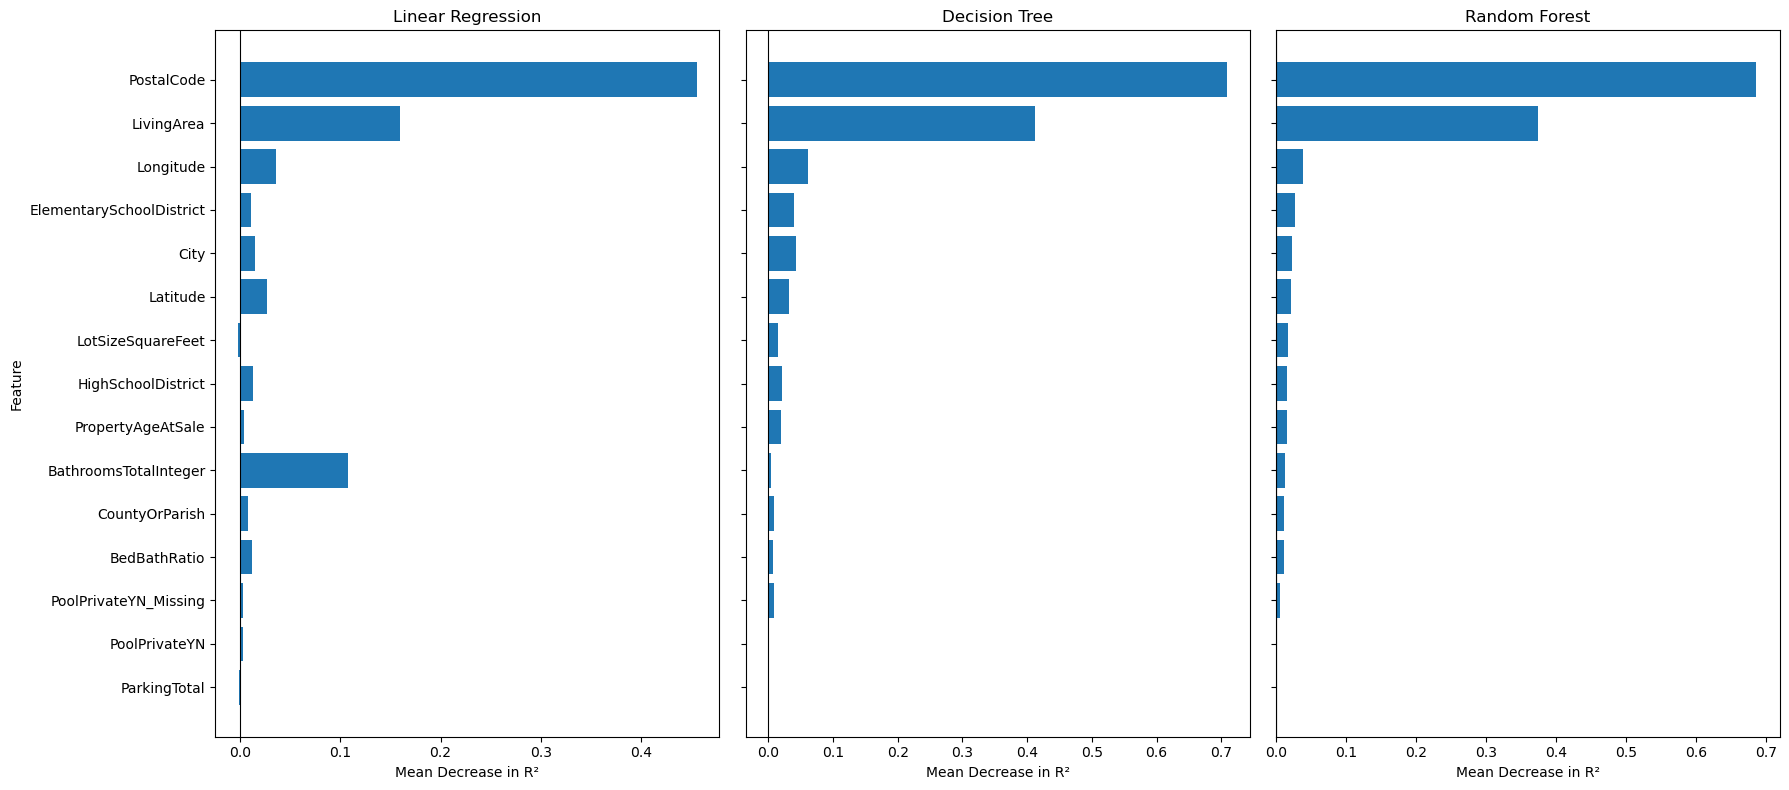

In [59]:
# Select the top 15 features based on Random Forest importance
top_features = feature_importance_df.head(15).iloc[::-1]

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)

for ax, model in zip(axes,["Linear Regression", "Decision Tree", "Random Forest"]):
    ax.barh(top_features.index, top_features[model])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(model)
    ax.set_xlabel("Mean Decrease in R²")

axes[0].set_ylabel("Feature")
plt.tight_layout()
plt.show()

In [60]:
# Generate predictions on the validation dataset
y_pred_val = np.expm1(random_forest_pipeline_fe.predict(X_validation_fe))

# Convert actual prices to the original dollar scale
y_actual_val = np.expm1(y_val)

# Calculate residuals(actual - predicted)
residuals_val = y_actual_val - y_pred_val

### Residual Analysis

Residual analysis was performed on the March 2026 validation set using the best-performing Random Forest model with both engineered feature types. Actual and predicted sale prices were compared on the original dollar scale to identify systematic prediction errors, outliers, and potential model limitations.

**Key Findings:**

The Random Forest model shows relatively accurate predictions for lower-priced and mid-priced properties, with increasing prediction errors at higher price ranges.

The residual plot exhibits a widening spread as predicted prices increase, suggesting heteroscedasticity. Additionally, the model tends to underestimate some high-priced properties. Overall, the model performs well on the validation set, although prediction accuracy is less consistent for expensive properties.

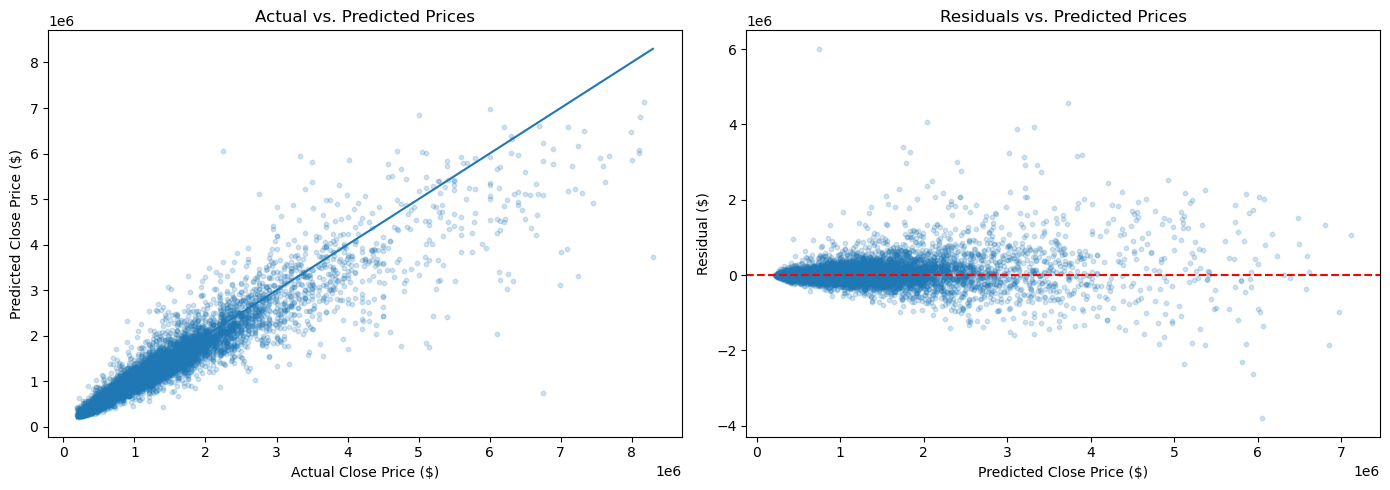

In [61]:
# Plot actual vs. predicted prices and residuals
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs. predicted prices
axes[0].scatter(y_actual_val, y_pred_val, alpha=0.2, s=10)
price_min = min(y_actual_val.min(), y_pred_val.min())
price_max = max(y_actual_val.max(), y_pred_val.max())

axes[0].plot([price_min, price_max], [price_min, price_max])
axes[0].set_xlabel("Actual Close Price ($)")
axes[0].set_ylabel("Predicted Close Price ($)")
axes[0].set_title("Actual vs. Predicted Prices")

# Residuals vs. predicted prices
axes[1].scatter(y_pred_val, residuals_val, alpha=0.2, s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Close Price ($)")
axes[1].set_ylabel("Residual ($)")
axes[1].set_title("Residuals vs. Predicted Prices")

plt.tight_layout()
plt.show()

### Validation Performance by Property Price Range

To further evaluate the Random Forest model, validation predictions were grouped into five price ranges based on actual sale prices. R², MAPE, and MdAPE were calculated for each group to examine how prediction accuracy varies across different property values.

In [62]:
# Create a DataFrame with actual and predicted validation prices
price_analysis_val_df = pd.DataFrame({"ActualPrice": np.asarray(y_actual_val), "PredictedPrice": np.asarray(y_pred_val)})

# Define property price ranges
price_bins = [0, 500000, 1000000, 2000000, 4000000, np.inf]
price_labels = ["Under $500K", "$500K–$1M", "$1M–$2M", "$2M–$4M", "$4M+"]

# Assign properties to price ranges based on actual sale prices
price_analysis_val_df["PriceRange"] = pd.cut(price_analysis_val_df["ActualPrice"], bins=price_bins,
                                             labels=price_labels,right=False)

# Calculate validation metrics for each price range
price_range_results_val = []

for price_range, group in price_analysis_val_df.groupby("PriceRange", observed=True):

    actual = group["ActualPrice"]
    predicted = group["PredictedPrice"]

    price_range_results_val.append({"Price Range": price_range, "Count": len(group),\
        "R²": r2_score(actual, predicted) if len(group) >= 2 else np.nan, "MAPE (%)": mape(actual, predicted),
        "MdAPE (%)": mdape(actual, predicted)})

# Create validation results DataFrame
price_range_results_val_df = pd.DataFrame(price_range_results_val)
display(price_range_results_val_df)

,Price Range,Count,R²,MAPE (%),MdAPE (%)
0,Under $500K,1635,0.021819,13.241460,7.525665
1,$500K–$1M,4908,0.431470,8.949443,6.039698
2,$1M–$2M,3361,0.183470,11.975389,9.032086
3,$2M–$4M,1221,-0.075829,14.924841,11.665060
4,$4M+,265,-0.887107,21.373592,19.033967


**Key Findings:**

* Best performance: Properties priced between $500K and $1M had the lowest prediction errors (MAPE = 8.95%, MdAPE = 6.04%).

* Higher-priced properties: Prediction errors increased for more expensive homes, with the highest MAPE (21.37%) observed for properties above $4M.

* R²: Negative values for properties above $2M indicate weaker performance within these price ranges, although R² should be interpreted cautiously because each group has a restricted range of actual prices.

* Overall, the model performs best for mid-priced properties, while higher-priced properties remain more challenging to predict.

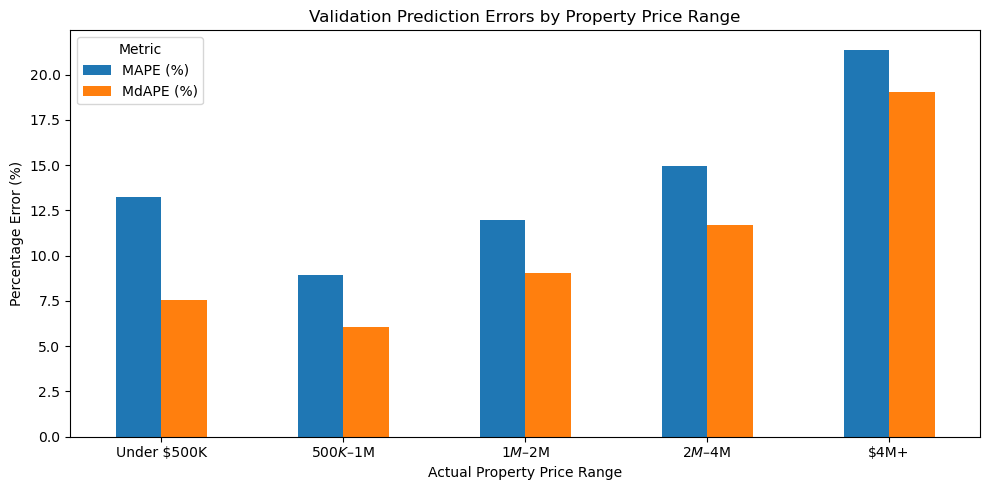

In [63]:
# Plot validation MAPE and MdAPE by property price range
ax = price_range_results_val_df.plot(x="Price Range", y=["MAPE (%)", "MdAPE (%)"], kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Validation Prediction Errors by Property Price Range")
ax.set_xlabel("Actual Property Price Range")
ax.set_ylabel("Percentage Error (%)")
ax.legend(title="Metric")
plt.tight_layout()
plt.show()

### Test Set Evaluation

The six feature-engineered models were evaluated on the held-out April 2026 test dataset using the same fitted pipelines from the March validation evaluation. Performance was measured using R², MAPE, and MdAPE on the original dollar scale to assess generalization to unseen property sales.

In [64]:
# Evaluate feature-engineered models on the April 2026 test dataset
test_results_fe = []

for name, pipeline, X_test_model in [
    ("Linear Regression + Ratio", linear_regression_pipeline_ratio, X_test_ratio),
    ("Decision Tree + Ratio", decision_tree_pipeline_ratio, X_test_ratio),
    ("Random Forest + Ratio", random_forest_pipeline_ratio, X_test_ratio),
    ("Linear Regression + Ratio + School Districts", linear_regression_pipeline_fe, X_test_fe),
    ("Decision Tree + Ratio + School Districts", decision_tree_pipeline_fe, X_test_fe),
    ("Random Forest + Ratio + School Districts", random_forest_pipeline_fe, X_test_fe)]:

    # Generate predictions on the original ClosePrice scale
    test_predictions = np.expm1(pipeline.predict(X_test_model))

    test_r2 = r2_score(np.expm1(y_test), test_predictions)
    test_mape = mape(np.expm1(y_test), test_predictions)
    test_mdape = mdape(np.expm1(y_test), test_predictions)

    # Store model results
    test_results_fe.append({"Model": name, "Test R²": test_r2, "Test MAPE (%)": test_mape, "Test MdAPE (%)": test_mdape})
# Create comparison DataFrame
test_results_fe_df = pd.DataFrame(test_results_fe)
display(test_results_fe_df.round(4))

,Model,Test R²,Test MAPE (%),Test MdAPE (%)
0,Linear Regression + Ratio,0.8088,15.7666,11.8724
1,Decision Tree + Ratio,0.8531,13.9170,9.5923
2,Random Forest + Ratio,0.8875,11.7304,7.8950
3,Linear Regression + Ratio + School Districts,0.8101,15.6655,11.8089
4,Decision Tree + Ratio + School Districts,0.8472,14.0011,9.6161
5,Random Forest + Ratio + School Districts,0.8861,11.6950,7.9034


**Key Findings:**

* Random Forest achieved the best overall test performance, with the baseline model obtaining the highest R² (0.8882) and lowest MdAPE (7.87%).

* Feature engineering produced only minor changes in performance. Adding school district features slightly improved Random Forest MAPE but did not improve R² or MdAPE.

* Decision Tree showed a small improvement in R² when adding the bedroom-to-bathroom ratio, while Linear Regression benefited slightly from both engineered feature types.

* Overall, Random Forest consistently outperformed the other models. The engineered features provided limited additional predictive value, suggesting that the baseline features already capture much of the information needed for price prediction.

In [65]:
# Combine baseline and feature-engineered test results
test_all_results_df = pd.concat([test_comparison_df, test_results_fe_df], ignore_index=True)
display(test_all_results_df.round(4))

,Model,Test R²,Test MAPE (%),Test MdAPE (%)
0,Linear Regression,0.8091,15.8561,11.9001
1,Default Decision Tree,0.7853,16.4697,10.7924
2,Regularized Decision Tree,0.8516,13.9558,9.5658
3,Random Forest,0.8882,11.7267,7.8680
4,Linear Regression + Ratio,0.8088,15.7666,11.8724
5,Decision Tree + Ratio,0.8531,13.9170,9.5923
6,Random Forest + Ratio,0.8875,11.7304,7.8950
7,Linear Regression + Ratio + School Districts,0.8101,15.6655,11.8089
8,Decision Tree + Ratio + School Districts,0.8472,14.0011,9.6161
9,Random Forest + Ratio + School Districts,0.8861,11.6950,7.9034
